# NN_L7_attention_example

**Lecture 7 of Neural Networks and Deep Learning (NN), attention and transformers. Attention weights of pretrained FinBERT, averaged over the 12 heads, in layers 6 and 12, for one bearish test tweet.**

Neural Networks and Deep Learning (NN), Lecture 7 · Daniel Traian Pele, Bucharest University of Economic Studies

[Open in Colab](https://colab.research.google.com/github/danpele/NEURAL_BIZ/blob/main/Quantlets/L7/NN_L7_attention_example/NN_L7_attention_example.ipynb)

In [1]:
import os
# course data: the local copy of the repository if there is one, else the public repository on GitHub
_LOCAL = os.path.join('..', '..', '..', 'data', 'clean')
DATA = _LOCAL + os.sep if os.path.isdir(_LOCAL) else 'https://raw.githubusercontent.com/danpele/NEURAL_BIZ/main/data/clean/'
REPO = os.path.join('..', '..', '..') + os.sep if os.path.isdir(_LOCAL) else 'https://raw.githubusercontent.com/danpele/NEURAL_BIZ/main/'

In [2]:
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
warnings.filterwarnings('ignore')
# course chart style: transparent background, no gridlines, legend at the bottom outside the axes, four-digit years
plt.rcParams.update({
    'figure.facecolor': 'none', 'axes.facecolor': 'none', 'savefig.transparent': True,
    'axes.grid': False, 'axes.spines.top': False, 'axes.spines.right': False,
    'axes.edgecolor': '#222222', 'axes.labelcolor': '#222222', 'xtick.color': '#222222', 'ytick.color': '#222222',
    'text.color': '#222222', 'font.size': 11, 'axes.labelsize': 11, 'legend.fontsize': 10.5, 'legend.frameon': False,
    'lines.linewidth': 1.4, 'font.family': 'DejaVu Sans'})
SERIES = ['#2a78d6', '#eb6834', '#1baf7a', '#eda100', '#e87ba4', '#008300', '#6250d6', '#e34948']
PAL = {'data': '#2a78d6', 'model': '#eb6834', 'benchmark': '#1baf7a', 'alt': '#eda100',
       'train': '#2a78d6', 'valid': '#eb6834', 'test': '#6250d6', 'positive': '#e34948', 'negative': '#2a78d6'}


def legend_bottom(fig, ncol=4):
    h, l_ = [], []
    for ax in fig.axes:
        for hh, ll in zip(*ax.get_legend_handles_labels()):
            if ll not in l_:
                h.append(hh); l_.append(ll)
    if h:
        fig.legend(h, l_, loc='lower center', ncol=min(ncol, len(h)), bbox_to_anchor=(0.5, 0.0), frameon=False)


def show(key, label, value):
    # print a number of the slide; [key] = its name in lectures/Lk/Lk_numbers.json
    print(f'{label} = {value}   [{key}]')

Rows = queries, columns = keys; each row sums to one.

tokens in the tweet = 13   [example.n_tokens]
largest attention of [CLS] on a word, layer 6 (%) = 5.7   [example.cls_top_pct]


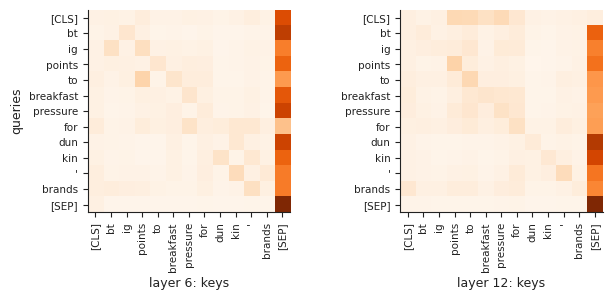

In [3]:
A6 = pd.read_csv(REPO + 'lectures/L7/results/' + 'attention_example_layer6.csv', index_col=0)
A12 = pd.read_csv(REPO + 'lectures/L7/results/' + 'attention_example_last.csv', index_col=0)
toks = [str(x).replace('##', '') for x in A6.index]
show('example.n_tokens', 'tokens in the tweet', len(toks))
show('example.cls_top_pct', 'largest attention of [CLS] on a word, layer 6 (%)', round(100 * float(A6.values[0, 1:-1].max()), 1))
fig, axs = plt.subplots(1, 2, figsize=(6.6, 3.1))
for ax, A, lab in [(axs[0], A6.values, 'layer 6: keys'), (axs[1], A12.values, 'layer 12: keys')]:
    ax.imshow(A, cmap='Oranges', vmin=0, vmax=min(1, A.max()))
    ax.set_xticks(range(len(toks))); ax.set_xticklabels(toks, rotation=90, fontsize=7.5)
    ax.set_yticks(range(len(toks))); ax.set_yticklabels(toks, fontsize=7.5); ax.set_xlabel(lab, fontsize=9)
axs[0].set_ylabel('queries', fontsize=9)
fig.tight_layout()
fig.savefig('attention_example.png', dpi=200, transparent=True, bbox_inches='tight')
plt.show()